# Feature Extraction and Price Prediction for Mobile Phones

In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

# Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Ridge

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

from sklearn.inspection import permutation_importance

import warnings
warnings.filterwarnings('ignore')

# Load Dataset

In [9]:
import pandas as pd

df = pd.read_excel(r"C:\Users\Nakshatra\Downloads\Processed_Flipdata.xlsx")

df.head()

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,11999
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,5649
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,8999


# Data Exploration

In [10]:
print("Dataset Shape:", df.shape)

print("\nFirst Five Records:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Shape: (541, 12)

First Five Records:


,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,11999
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,5649
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,8999



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     541 non-null    int64  
 1   Model          541 non-null    object 
 2   Colour         541 non-null    object 
 3   Memory         541 non-null    int64  
 4   RAM            541 non-null    int64  
 5   Battery_       541 non-null    int64  
 6   Rear Camera    541 non-null    object 
 7   Front Camera   541 non-null    object 
 8   AI Lens        541 non-null    int64  
 9   Mobile Height  541 non-null    float64
 10  Processor_     541 non-null    object 
 11  Prize          541 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 50.8+ KB

Statistical Summary:


,Unnamed: 0,Memory,RAM,Battery_,AI Lens,Mobile Height,Prize
count,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000
mean,289.711645,110.550832,5.397412,4871.587800,0.062847,16.431201,16228.375231
std,182.359185,60.600694,1.984923,780.148862,0.242911,2.523553,10793.588322
min,0.000000,16.000000,2.000000,800.000000,0.000000,4.500000,920.000000
25%,135.000000,64.000000,4.000000,5000.000000,0.000000,16.510000,9290.000000
50%,273.000000,128.000000,6.000000,5000.000000,0.000000,16.710000,13499.000000
75%,434.000000,128.000000,8.000000,5000.000000,0.000000,16.940000,19280.000000
max,642.000000,256.000000,8.000000,7000.000000,1.000000,41.940000,80999.000000



Missing Values:
Unnamed: 0       0
Model            0
Colour           0
Memory           0
RAM              0
Battery_         0
Rear Camera      0
Front Camera     0
AI Lens          0
Mobile Height    0
Processor_       0
Prize            0
dtype: int64

Duplicate Records:
0


 # Data preprocesssing

In [11]:
# Remove unnecessary index column
df = df.drop(columns=['Unnamed: 0'], errors='ignore')

# Remove duplicate records
df = df.drop_duplicates()

# Check missing values
print(df.isnull().sum())

# Check dataset
print("Final Dataset Shape:", df.shape)

Model            0
Colour           0
Memory           0
RAM              0
Battery_         0
Rear Camera      0
Front Camera     0
AI Lens          0
Mobile Height    0
Processor_       0
Prize            0
dtype: int64
Final Dataset Shape: (531, 11)


 # Exploratory Data Analysis (EDA)

 ## Price Distribution

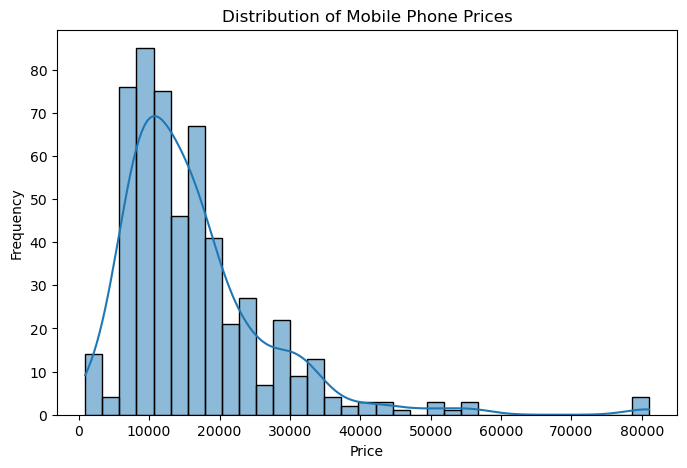

In [12]:
plt.figure(figsize=(8,5))

sns.histplot(df['Prize'], kde=True)

plt.title('Distribution of Mobile Phone Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')

plt.show()

## RAM vs Price

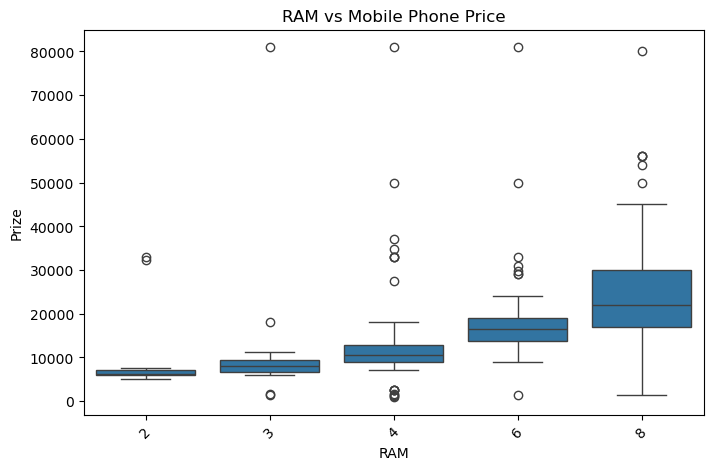

In [13]:
plt.figure(figsize=(8,5))

sns.boxplot(x='RAM', y='Prize', data=df)

plt.title('RAM vs Mobile Phone Price')

plt.xticks(rotation=45)
plt.show()

 ## Memory vs Price

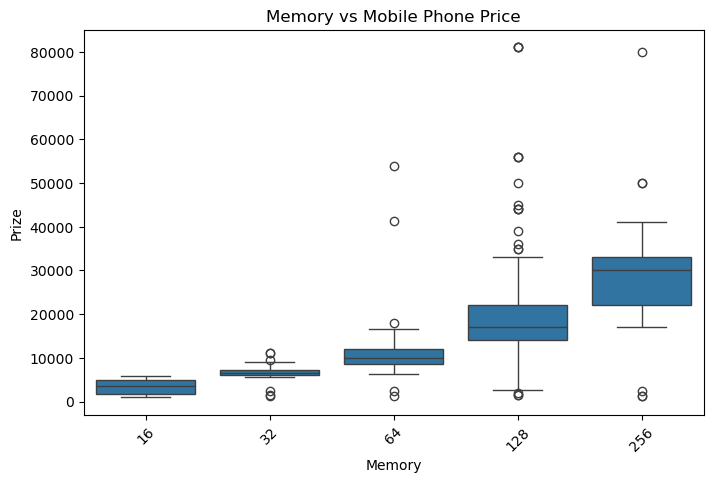

In [14]:
plt.figure(figsize=(8,5))

sns.boxplot(x='Memory', y='Prize', data=df)

plt.title('Memory vs Mobile Phone Price')

plt.xticks(rotation=45)
plt.show()

 # Feature Extraction and Selection

In [15]:
# Separate features and target
X = df.drop('Prize', axis=1)

y = df['Prize']

# Identify categorical and numerical columns
categorical_cols = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

numerical_cols = X.select_dtypes(
    exclude=['object', 'category']
).columns.tolist()

print("Categorical Features:", categorical_cols)

print("Numerical Features:", numerical_cols)

Categorical Features: ['Model', 'Colour', 'Rear Camera', 'Front Camera', 'Processor_']
Numerical Features: ['Memory', 'RAM', 'Battery_', 'AI Lens', 'Mobile Height']


 # Data Encoding and Scaling

In [22]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

 # Train-Test Split

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (424, 10)
Testing Data: (107, 10)


 # Model Building

In [20]:
models = {
    'Ridge Regression': Ridge(),

    'Random Forest': RandomForestRegressor(
        n_estimators=400,
        random_state=42
    ),

    'Extra Trees': ExtraTreesRegressor(
        n_estimators=400,
        random_state=42
    ),

    'Gradient Boosting': GradientBoostingRegressor(
        random_state=42
    )
}

trained_models = {}

results = []

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    trained_models[name] = pipeline

    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'R2 Score': r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

display(results_df.sort_values('MAE'))

,Model,MAE,RMSE,R2 Score
2,Extra Trees,1616.879393,4039.841740,0.845207
1,Random Forest,1886.813895,4177.861085,0.834450
0,Ridge Regression,2100.483021,5108.530169,0.752478
3,Gradient Boosting,2642.778207,6095.935377,0.647546


 # Model Evaluation

In [21]:
best_model_name = results_df.sort_values(
    'MAE'
).iloc[0]['Model']

best_model = trained_models[best_model_name]

predictions = best_model.predict(X_test)

print("Best Model:", best_model_name)

print("MAE:", mean_absolute_error(y_test, predictions))

print(
    "RMSE:",
    np.sqrt(mean_squared_error(y_test, predictions))
)

print("R2 Score:", r2_score(y_test, predictions))

Best Model: Extra Trees
MAE: 1616.8793925233647
RMSE: 4039.8417396615964
R2 Score: 0.8452074625565159


 # Feature Importance Analysis

 ## Permutation importance se pata chalega ki kaunse features model ki prediction performance ko sabse zyada affect karte hain.

In [23]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=15,
    random_state=42,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance.importances_mean
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance)

,Feature,Importance
2,Memory,2480.289875
3,RAM,1984.605467
6,Front Camera,1813.692252
0,Model,736.745826
9,Processor_,684.244420
5,Rear Camera,623.963280
4,Battery_,364.589040
8,Mobile Height,120.115660
7,AI Lens,56.552609
1,Colour,47.394360


 # Feature Importance Graph

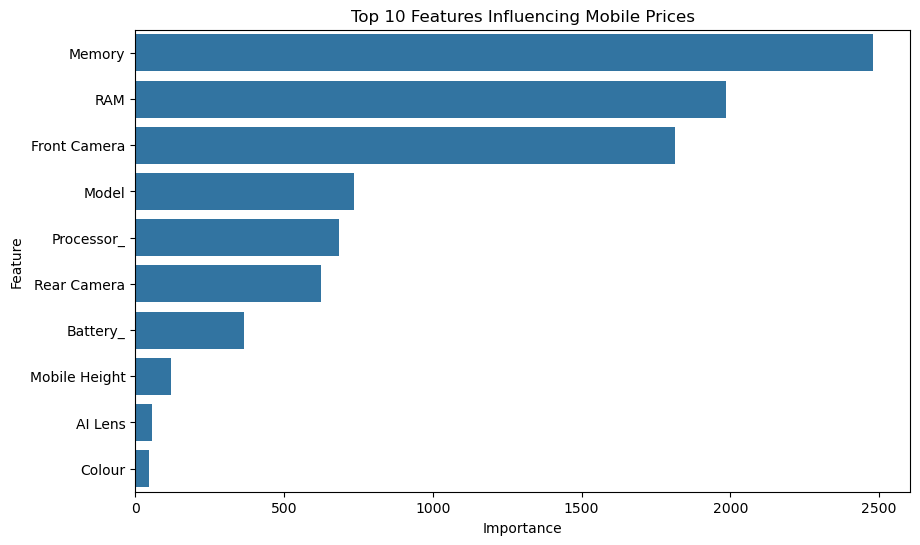

In [24]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Features Influencing Mobile Prices')

plt.show()

 # Actual vs Predicted Price

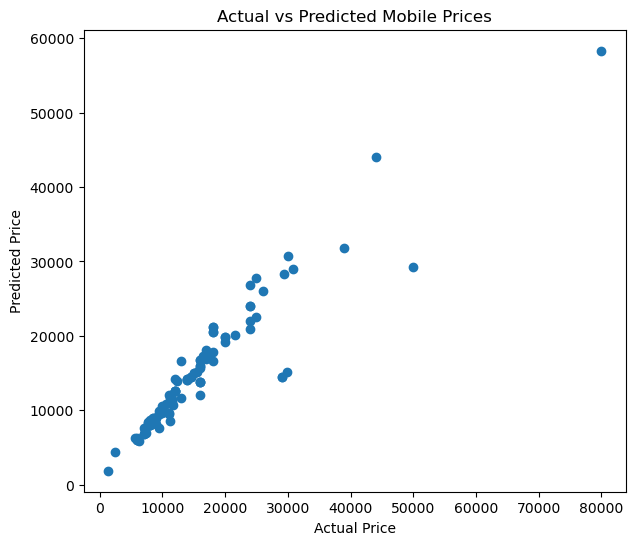

In [25]:
plt.figure(figsize=(7,6))

plt.scatter(y_test, predictions)

plt.xlabel('Actual Price')

plt.ylabel('Predicted Price')

plt.title('Actual vs Predicted Mobile Prices')

plt.show()

 # Save the Trained Model

In [33]:
import joblib

joblib.dump(
    best_model,
    'mobile_price_prediction_model.pkl'
)

print("Model Saved Successfully!")

Model Saved Successfully!


 # Predict Price of a New Mobile

In [34]:
new_mobile = pd.DataFrame([{
    col: X_train[col].iloc[0]
    for col in X.columns
}])

predicted_price = best_model.predict(new_mobile)

print(
    "Predicted Mobile Price:",
    round(predicted_price[0], 2)
)

Predicted Mobile Price: 8990.0


 ## The project successfully demonstrates the application of Machine Learning techniques to predict mobile phone prices based on their technical specifications. Through data exploration and preprocessing, the dataset was cleaned, duplicate records were removed, and categorical features were converted into a numerical format suitable for model training.Four regression algorithms—Ridge Regression, Random Forest, Extra Trees, and Gradient Boosting—were developed and evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² score. Among these, the Extra Trees Regressor achieved the best performance, with an R² score of 84.52%, indicating that the model explains a substantial proportion of the variation in mobile phone prices.Feature importance analysis identified Memory, Front Camera, and RAM as the most influential predictive features, followed by Rear Camera, Battery Capacity, and Processor. These findings highlight the importance of hardware specifications in understanding mobile phone pricing patterns.Overall, this project provides a data-driven approach to mobile phone price estimation. The developed model can help businesses understand pricing patterns, compare product specifications, support pricing decisions, and improve market positioning. However, predictions should be validated using updated market data before being applied to real-world pricing decisions.Final Outcome: A trained machine learning model capable of estimating mobile phone prices from product specifications, supported by performance evaluation and feature importance analysis.

 # Conclusion